# Change-Point Task Design Exploration: Choosing SNRs

> **Outcome.** This notebook chose the SNRs of the 2026 change-point cohort: candidate A below
> (SNR 0.2 and 0.6; `tc_step_mean` 0.01 and 0.03 at step SD 0.05), which is what that cohort ran.
> "2025 task" below is the design it started from (SNR 0.2 and 0.4). The original run grounded the
> bound grid in the 2025 cohort's bias-corrected bounds; `pigeon` no longer loads those data, so
> that section now shows the 2026 cohort's raw bounds. The rest does not use data, but its numbers
> changed when a simulator bug was fixed: the original run calibrated each simulated participant's
> change-point step with NDT fixed at 1 step, while the change-point simulations used NDT 0 or 1;
> both now use 0 or 1. With the fix, 0.2 -> 0.6 is no longer the top-ranked pair within the
> historical ratio range (6th by absolute, 4th by relative benefit; 0.3 -> 1.0 is 1st), and
> candidates A and B tie in the deep dive; both still clearly beat the 2025 pair, and the
> `coins_lost = 4` check is unchanged.

## Background

The 2025 MXSC change-point (CP) task used generative means **0.01 / 0.02** (SNR 0.2 / 0.4,
`generative_std = 0.05`) for the Low/High SNR conditions. Those values were chosen from the
**normative** model — the SNR pair (and implied optimal bounds) that would be ideal *if*
participants used the normative bound both before and after the change point.

They clearly don't: `Figure03_boundSummary` / `Figure04_RRvsBound` show bounds far from
normative and highly variable across subjects. That breaks the logic behind the original SNR
choice — there is no reason to expect an SNR pair optimized for normative bounds to also be a
good pair for revealing *whether/how much participants adjust their (non-normative) bound* at
a change point.

The task is also being redesigned in a way that matters here (see `task/MXSC/PigeonTask.js`,
`calculate_median` / `check_rt_extremity`): the change-point step is no longer a fixed,
pre-registered trial step. It is calibrated **per participant**, as the (rounded) median RT
(in steps) of that participant's own preceding fixed-SNR block, with an automatic screen
(`RT_TOO_FAST_STEPS=3`, `RT_TOO_SLOW_STEPS=25`, `RT_TIMEOUT_FRACTION_MAX=0.2`) that ends the
session if a participant's RTs on that calibration block are unusable. So the CP timing is
already locked to "roughly when this participant tends to decide" — we don't need to search
over CP step as a free design parameter; we need to search over **SNR** (which determines,
together with whatever bound the participant happens to be using, both the calibrated CP
timing and how much a bound change at that CP would matter).

## Goal of this notebook

For a grid of candidate (SNR_low, SNR_high) pairs roughly within the range used across this
task and its predecessors (MX/MXSC, OL-MX-PD, and the original pilot task), and for a *wide,
non-normative* range of plausible pre-CP bounds, estimate:

- how much expected reward rate (RR) would change if a participant adjusted their bound
  optimally after the CP, vs. kept the same bound as before the CP ("benefit of adjusting"),
- whether the SNR/bound combination is even usable (RTs not floor/ceiling'd against the task's
  own `check_rt_extremity` thresholds),

and use that to propose a short list of concrete SNR pairs for a pilot, plus the resulting
`tc_step_mean` values for `PigeonTaskConditions.xlsx`.

## Modeling simplification: normalized units

Bound-crossing statistics for a random walk with per-step mean `mu` and SD `sigma` depend only
on `mu/sigma` (SNR) and `bound/sigma`. `sigma` itself is a display/calibration constant (the
task uses `generative_std = 0.05`), not a cognitively meaningful design choice. So
everywhere below, SNR and bound are both expressed **normalized to `sigma = 1`**; physical
values for the actual task are obtained by multiplying by `G_STD_PHYSICAL = 0.05` (the
MXSC calibration) at the end.


In [1]:
import time, itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pigeon.simulation import simulate_trials
from pigeon.data import get_good_trial_array
from pigeon.stopping import get_stopping_model_trials

RNG_SEED = 20260805
G_STD_PHYSICAL = 0.05   # MXSC generative_std -- normalized units x this = physical units

# Task constants, copied from task/MXSC/PigeonTask.js so the feasibility screen here
# matches the actual task's own RT-extremity check exactly.
STEPS_MAX_PER_TRIAL     = 50    # STEPS_MAX_PER_TRIAL
NDT_MIN, NDT_MAX        = 2, 3  # -> NDT in {0, 1} steps, same convention as the archived Make_RRMatrix.ipynb
RT_TOO_FAST_STEPS       = 3     # check_rt_extremity
RT_TOO_SLOW_STEPS       = 25    # check_rt_extremity
RT_TIMEOUT_FRACTION_MAX = 0.2   # check_rt_extremity
STEPS_PER_BLOCK         = 1000  # tc_steps_max, PigeonTaskConditions.xlsx (change_low/change_high rows)

print('Setup OK')


Setup OK


## Historical SNR range

A quick inventory of SNR values actually used across task versions, for calibrating what
"roughly within range" means:

| Source | generative mean(s) | generative std | SNR |
|---|---|---|---|
| **MXSC**, 2025 cohort (this notebook's starting point) | 0.01, 0.02 | 0.05 | 0.20, 0.40 |
| **MXSC**, 2026 cohort (chosen here: candidate A) | 0.01, 0.03 | 0.05 | 0.20, 0.60 |
| **OL-MX-PD**, `PigeonSNRSet01Conditions.xlsx` | 0.05 | 0.15 | 0.33 |
| **OL-MX-PD**, `PigeonSNRSet02Conditions.xlsx` | 0.15 | 0.15 | 1.00 |
| Original pilot (`VisualizeSNRs.ipynb`, `QuickVisSim_Pigeon`) | 5, 7.5, 10, 15 | 20-40 | 0.125-0.75 |

So across this project's task history, SNR has ranged roughly **0.13 - 1.0**, with within-task
low/high ratios of about **1.5x-3x** where a ratio existed (MXSC: 2x; pilot: up to 3x). The
SNR grid explored below spans a bit wider than this (0.15-1.2) so the sweep isn't artificially
boxed in right at the historical edges, but the final candidate recommendation is kept within
this historical range as requested.


In [2]:

# Candidate SNR levels (normalized, sigma=1) and bound grid (normalized) to search over.
SNR_LEVELS = [0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0, 1.2]

# Log-spaced normalized bound grid: 0.1 (near-instant response) to 8 (near/beyond the
# empirical p99 -- see below), used both for the RT-feasibility map and as the pool of
# candidate post-CP bounds to search over for the "optimal adjustment".
BOUND_GRID = np.round(np.geomspace(0.1, 8, 15), 3)

print('SNR levels:', SNR_LEVELS)
print('Bound grid (normalized):', BOUND_GRID)


SNR levels: [0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0, 1.2]
Bound grid (normalized): [0.1   0.137 0.187 0.256 0.35  0.478 0.654 0.894 1.223 1.673 2.287 3.128
 4.278 5.85  8.   ]


## Grounding the plausible bound range in real data

We are explicitly *not* assuming participants use anything close to the normative bound. But
it's still useful to know where real MXSC bounds actually fall, as a sanity check on the bound
grid above. Per subject and block, the median direct bound measure (`get_bounds`, raw positions)
over the trials `Figure06_cpSummary.ipynb` uses (`get_stopping_model_trials`) that pass the
standard filter (`get_good_trial_array`), pooled over all four blocks. These are the 2026
cohort's bounds (see the note at the top); the original run used the 2025 cohort's bias-corrected
bounds, with a median of about 2.5 in normalized units (the value used as the representative
pre-CP bound in the robustness check below).


In [3]:
_dt_mxsc = get_stopping_model_trials('MXSC', [1, 2, 3, 4], verbose=False)
_dt_mxsc = _dt_mxsc[get_good_trial_array(_dt_mxsc)]
_all_bounds = _dt_mxsc.groupby(['subject_index', 'block_index']).abs_bound.median().to_numpy()

_pcts = [5, 25, 50, 75, 90, 99]
_pvals = np.percentile(_all_bounds, _pcts)
bound_percentiles = pd.DataFrame({
    'percentile': _pcts,
    'bound_physical': _pvals,
    'bound_normalized': _pvals / G_STD_PHYSICAL,
})
print(f'Median |bound| per subject and block, 2026 cohort, all four blocks (n = {len(_all_bounds)}):')
print(bound_percentiles.to_string(index=False))


Median |bound| per subject and block, 2026 cohort, all four blocks (n = 245):
 percentile  bound_physical  bound_normalized
          5        0.063019          1.260385
         25        0.095478          1.909566
         50        0.139628          2.792569
         75        0.188477          3.769531
         90        0.258653          5.173066
         99        0.389469          7.789370


## Simulation engine

`simulate_cp_batch` draws the random walk for a given (pre-SNR, post-SNR, switch step); the
bound only enters through the *stopping rule*, not the walk itself, so the same draw can be
reused to evaluate **every** candidate (pre-bound, post-bound) pair -- common random numbers
(CRN). That matters a lot here: the quantity of interest is a *difference* in reward rate
between bound choices, and CRN removes the sampling noise that would otherwise swamp small,
genuine differences (an earlier, non-CRN version of this sweep produced spurious negative
"benefit of adjusting" values purely from independent sampling noise between the curve and the
no-adjust point; this version is guaranteed non-negative by construction).

This adapts the archived `Make_RRMatrix.ipynb`'s `_simulate_cp_mean_coins` (same crossing-detection logic,
same `cp_step`/`switch_time` 1-indexed convention: steps `1..switch_time-1` use pre-CP
parameters, `switch_time..max_steps` use post-CP parameters) but splits it into a cacheable
random draw plus a cheap, RNG-free outcome function, and returns trial-level arrays (for a
renewal-reward RR estimate, `RR = E[reward] / E[steps]` -- the same reward-rate definition
used throughout the codebase, e.g. `matlab/Figure04_RRvsBound.m`: `rewardRate =
coinSummary/600`) rather than only a block-budget-truncated mean-coins summary.

Reward structure: `coins_gained=1, coins_lost=1`, matching the 2025
`change_low`/`change_high` rows of `PigeonTaskConditions.xlsx`. (Note `Make_RRMatrix.ipynb`
uses `coins_lost=4`, matching the historical block-2 default used for Figure06 -- the
finalists are re-checked under that cost below as a robustness check.)


In [4]:

def simulate_cp_batch(pre_snr, post_snr, switch_time, num_trials,
                       max_steps=STEPS_MAX_PER_TRIAL, ndt_min=NDT_MIN, ndt_max=NDT_MAX, rng=None):
    '''Draw the random component of a CP block (shared across every bound choice).

    Parameters
    ----------
    pre_snr, post_snr : float
        Normalized generative means (sigma=1) before/after the change point.
    switch_time : int
        1-indexed step at which the CP occurs (Make_RRMatrix.ipynb convention).
    num_trials : int
    rng : np.random.Generator or None

    Returns
    -------
    DV : (num_trials, max_steps+1) cumulative walk
    ndts : (num_trials,) non-decision times
    '''
    if rng is None:
        rng = np.random.default_rng()
    mean_steps = np.full(max_steps, pre_snr, dtype=float)
    mean_steps[switch_time - 1:] = post_snr
    noise = rng.normal(mean_steps[None, :], 1.0, size=(num_trials, max_steps))
    DV = np.concatenate([np.zeros((num_trials, 1)), np.cumsum(noise, axis=1)], axis=1)
    ndts = rng.integers(1, ndt_max - ndt_min + 2, size=num_trials) + (1 - ndt_min)
    return DV, ndts


def outcome_for_bounds(DV, ndts, pre_bound, post_bound, switch_time, max_steps=STEPS_MAX_PER_TRIAL):
    '''RNG-free: choices/RTs for one (pre_bound, post_bound) pair given a cached DV/ndts batch.'''
    num_trials = DV.shape[0]
    bound_steps = np.full(max_steps, pre_bound, dtype=float)
    bound_steps[switch_time - 1:] = post_bound

    crossed = np.abs(DV[:, :max_steps]) >= bound_steps[None, :]
    any_c = crossed.any(axis=1)
    first_k = np.argmax(crossed, axis=1)

    rts = np.full(num_trials, max_steps, dtype=int)
    choices = np.full(num_trials, np.nan)

    normal = any_c & (first_k > 0)
    rows = np.where(normal)[0]
    k = first_k[rows]
    rts[rows] = np.minimum(k + ndts[rows] + 1, max_steps)
    choices[rows] = (DV[rows, k] > 0).astype(float)
    # ss==0 crossings only arise at bound==0, outside the grids used in this notebook.
    return choices, rts


def compute_rr(choices, rts, coins_gained=1.0, coins_lost=1.0):
    '''Renewal reward rate: E[reward] / E[steps], coins per step.'''
    correct = choices == 1
    error = choices == 0
    reward = np.where(correct, coins_gained, np.where(error, -coins_lost, 0.0))
    return float(reward.mean() / rts.mean())


def calibrate_fixed_block(snr, bound, num_trials=20000, rng=None):
    '''Fixed-SNR/bound calibration block, matching PigeonTask.js exactly:
    switch_time = round(median RT in steps); flags RT-extremity per check_rt_extremity.
    Uses pigeon.simulation.simulate_trials directly (this *is* a plain fixed-bound block).
    '''
    if rng is None:
        rng = np.random.default_rng()
    choices, rts, *_ = simulate_trials(
        generative_mean=snr, generative_std=1.0, num_trials=num_trials,
        max_steps=STEPS_MAX_PER_TRIAL, bound_mean=bound, bound_std=0.0,
        ndt_min=NDT_MIN - 2, ndt_max=NDT_MAX - 2, rng=rng, return_steps=False,  # NDT {0, 1}, as in simulate_cp_batch
    )
    median_rt = float(np.median(rts))
    timeout_frac = float(np.mean(rts >= STEPS_MAX_PER_TRIAL))
    if median_rt < RT_TOO_FAST_STEPS:
        flag = 'too_fast'
    elif median_rt > RT_TOO_SLOW_STEPS or timeout_frac > RT_TIMEOUT_FRACTION_MAX:
        flag = 'too_slow'
    else:
        flag = 'ok'
    switch_time = max(1, int(round(median_rt)))
    return switch_time, median_rt, timeout_frac, flag

print('Simulation engine defined.')


Simulation engine defined.


## Feasibility map

For every (SNR, bound) combination in the grids above, simulate a fixed-SNR calibration
block and apply the task's own `check_rt_extremity` thresholds. This tells us which parts of
the (SNR, bound) space would even survive the real task's screening -- independent of the CP
question, this constrains which bounds are "live" candidates for a given SNR at all.


In [5]:

rng = np.random.default_rng(RNG_SEED)
N_CALIB = 20000

feas = {}
t0 = time.time()
for snr in SNR_LEVELS:
    for b in BOUND_GRID:
        feas[(snr, b)] = calibrate_fixed_block(snr, b, num_trials=N_CALIB, rng=rng)
print(f'Feasibility grid: {len(feas)} (SNR, bound) cells in {time.time()-t0:.1f}s')

feas_df = pd.DataFrame(
    [(snr, b, *feas[(snr, b)]) for snr in SNR_LEVELS for b in BOUND_GRID],
    columns=['snr', 'bound', 'switch_time', 'median_rt', 'timeout_frac', 'flag'],
)


Feasibility grid: 135 (SNR, bound) cells in 1.1s


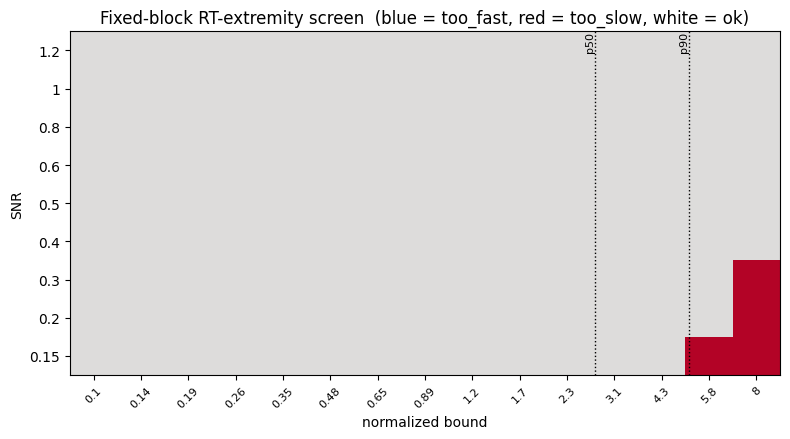

4 / 135 (SNR, bound) cells fail the RT-extremity screen (all at the bound-grid extremes).


In [6]:

fig, ax = plt.subplots(figsize=(8, 4.5))
flag_code = feas_df['flag'].map({'too_fast': -1, 'ok': 0, 'too_slow': 1}).to_numpy()
grid = flag_code.reshape(len(SNR_LEVELS), len(BOUND_GRID))
im = ax.imshow(grid, aspect='auto', cmap='coolwarm', vmin=-1, vmax=1, origin='lower')
ax.set_xticks(range(len(BOUND_GRID)))
ax.set_xticklabels([f'{b:.2g}' for b in BOUND_GRID], rotation=45, fontsize=8)
ax.set_yticks(range(len(SNR_LEVELS)))
ax.set_yticklabels([f'{s:.2g}' for s in SNR_LEVELS])
ax.set_xlabel('normalized bound')
ax.set_ylabel('SNR')
ax.set_title('Fixed-block RT-extremity screen  (blue = too_fast, red = too_slow, white = ok)')
for p, lbl in zip(np.percentile(_all_bounds / G_STD_PHYSICAL, [50, 90]), ['p50', 'p90']):
    xi = np.interp(p, BOUND_GRID, np.arange(len(BOUND_GRID)))
    ax.axvline(xi, color='k', linestyle=':', linewidth=1)
    ax.text(xi, len(SNR_LEVELS) - 0.5, lbl, rotation=90, va='top', ha='right', fontsize=8)
plt.tight_layout()
plt.show()

n_bad = (feas_df['flag'] != 'ok').sum()
print(f'{n_bad} / {len(feas_df)} (SNR, bound) cells fail the RT-extremity screen (all at the bound-grid extremes).')


## Main screening sweep

For every SNR pair `(lo, hi)` with `lo < hi` from `SNR_LEVELS`, both directions
(`LowHigh`: pre=lo, post=hi; `HighLow`: pre=hi, post=lo -- matching
the archived `Make_RRMatrix.ipynb`'s `G_MEANS` / `G_MEANS[::-1]` convention), and a spread of plausible
pre-CP bounds `B_PRE_SCREEN` (chosen to span from near-instant responding up through and past
the empirical p90-p99 bound percentiles above -- i.e. deliberately *not* anchored on the
normative bound):

1. Calibrate `switch_time` from the pre-CP (SNR, bound) combination (exactly matching how the
   real task derives it).
2. Draw one CRN batch for `(pre_snr, post_snr, switch_time)`.
3. Evaluate RR at every candidate post-CP bound in `BOUND_GRID` (plus `b_pre` itself, to
   represent "no adjustment") from that one batch.
4. Record `benefit = RR(optimal post-CP bound) - RR(no adjustment)` -- the key quantity: how
   much reward rate is at stake if a participant does vs. doesn't adjust their bound at the CP.


In [7]:

B_PRE_SCREEN = [0.15, 0.3, 0.6, 1.2, 2.5, 5.0]
N_SWEEP = 100_000
COINS_GAINED, COINS_LOST = 1.0, 1.0

pairs = list(itertools.combinations(SNR_LEVELS, 2))
print(f'{len(pairs)} SNR pairs x 2 directions x {len(B_PRE_SCREEN)} pre-CP bounds '
      f'x {len(BOUND_GRID)} candidate post-CP bounds')

# Calibration for the B_PRE_SCREEN anchors not already covered by the feasibility grid above.
for snr in SNR_LEVELS:
    for b in B_PRE_SCREEN:
        if (snr, b) not in feas:
            feas[(snr, b)] = calibrate_fixed_block(snr, b, num_trials=N_CALIB, rng=rng)

rng = np.random.default_rng(RNG_SEED + 1)
rows = []
t0 = time.time()
for lo, hi in pairs:
    for direction, pre_snr, post_snr in [('LowHigh', lo, hi), ('HighLow', hi, lo)]:
        for b_pre in B_PRE_SCREEN:
            switch_time, median_rt, timeout_frac, flag = feas[(pre_snr, b_pre)]
            DV, ndts = simulate_cp_batch(pre_snr, post_snr, switch_time, N_SWEEP, rng=rng)

            eval_bounds = np.union1d(BOUND_GRID, [b_pre])
            rr_curve = np.empty(len(eval_bounds))
            for bi, b_post in enumerate(eval_bounds):
                ch, rt = outcome_for_bounds(DV, ndts, b_pre, b_post, switch_time)
                rr_curve[bi] = compute_rr(ch, rt, COINS_GAINED, COINS_LOST)

            i_pre = int(np.searchsorted(eval_bounds, b_pre))
            rr_noadjust = rr_curve[i_pre]
            best_i = int(np.argmax(rr_curve))
            rows.append(dict(
                lo=lo, hi=hi, direction=direction, b_pre=b_pre,
                switch_time=switch_time, pre_flag=flag, timeout_frac=timeout_frac,
                rr_noadjust=rr_noadjust, rr_opt=rr_curve[best_i], b_post_opt=eval_bounds[best_i],
                benefit=rr_curve[best_i] - rr_noadjust,
            ))
print(f'Sweep done in {time.time()-t0:.1f}s, {len(rows)} rows')

sweep_df = pd.DataFrame(rows)
sweep_df['ratio'] = sweep_df['hi'] / sweep_df['lo']
sweep_df['rel_benefit'] = sweep_df['benefit'] / sweep_df['rr_noadjust'].abs()
print('Min benefit (should be >= 0 by construction, CRN guarantees the argmax includes b_pre itself):',
      sweep_df['benefit'].min())


36 SNR pairs x 2 directions x 6 pre-CP bounds x 15 candidate post-CP bounds


Sweep done in 48.8s, 432 rows
Min benefit (should be >= 0 by construction, CRN guarantees the argmax includes b_pre itself): 0.0


## Ranking SNR pairs

Two views of "how much is at stake":

- **absolute benefit** (coins/step) -- directly comparable to `rr_noadjust` and to a per-block
  total (multiply by `STEPS_PER_BLOCK`),
- **relative benefit** (`benefit / |rr_noadjust|`) -- how big the effect is relative to the
  condition's own baseline reward rate; controls for the fact that higher-SNR conditions have
  mechanically higher absolute RR.

Both are summarized across the `B_PRE_SCREEN` anchors as **mean** (average payoff of adjusting,
across plausible pre-CP bounds a participant might be using) and **worst-case / min** (a
robustness check -- is there some plausible pre-CP bound for which this SNR pair gives almost
nothing to detect? With only 6 anchors this will often hit near-zero somewhere, since *any*
SNR pair has some pre-CP bound that happens to already be close to post-CP-optimal; treat mean,
not worst-case, as the primary ranking criterion for that reason).

Pairs are also restricted to those where every `B_PRE_SCREEN` anchor passed the RT-extremity
feasibility screen.


In [8]:

feasible = sweep_df[sweep_df['pre_flag'] == 'ok']
agg = feasible.groupby(['lo', 'hi', 'direction']).agg(
    worst_benefit=('benefit', 'min'), mean_benefit=('benefit', 'mean'),
    worst_rel=('rel_benefit', 'min'), mean_rel=('rel_benefit', 'mean'),
    n_feasible=('benefit', 'size'), ratio=('ratio', 'first'),
).reset_index()
agg = agg[agg['n_feasible'] == len(B_PRE_SCREEN)].drop(columns='n_feasible')

print(f'{len(agg)} / {len(pairs)*2} (pair, direction) combinations feasible across all {len(B_PRE_SCREEN)} pre-CP bounds.')
print()
print('Top 12 by mean absolute benefit of adjusting (all ratios):')
print(agg.sort_values('mean_benefit', ascending=False).head(12).to_string(index=False))


72 / 72 (pair, direction) combinations feasible across all 6 pre-CP bounds.

Top 12 by mean absolute benefit of adjusting (all ratios):
  lo  hi direction  worst_benefit  mean_benefit  worst_rel  mean_rel    ratio
0.15 1.0   HighLow       0.000164      0.035410   0.000579  0.253939 6.666667
0.15 1.2   HighLow       0.000103      0.032917   0.000326  0.210240 8.000000
0.20 1.0   HighLow       0.000344      0.031807   0.001221  0.216197 5.000000
0.15 0.8   HighLow       0.000234      0.030827   0.000986  0.253450 5.333333
0.20 1.2   HighLow       0.000155      0.029640   0.000489  0.181654 6.000000
0.20 0.8   HighLow       0.000284      0.027645   0.001181  0.216006 4.000000
0.30 1.0   HighLow       0.000210      0.026051   0.000745  0.163767 3.333333
0.30 1.2   HighLow       0.000114      0.024397   0.000362  0.138073 4.000000
0.30 0.8   HighLow       0.000059      0.021571   0.000244  0.156253 2.666667
0.40 1.0   HighLow       0.000043      0.021067   0.000152  0.125132 2.500000
0.15 0

In [9]:

HIST_RATIO_RANGE = (1.2, 3.5)  # roughly this task's + predecessors' historical low/high ratio range
in_range = agg[(agg['ratio'] >= HIST_RATIO_RANGE[0]) & (agg['ratio'] <= HIST_RATIO_RANGE[1])]

print(f'Top 12 by mean absolute benefit, restricted to historical ratio range {HIST_RATIO_RANGE}:')
print(in_range.sort_values('mean_benefit', ascending=False).head(12).to_string(index=False))
print()
print(f'Top 12 by mean RELATIVE benefit, restricted to historical ratio range {HIST_RATIO_RANGE}:')
print(in_range.sort_values('mean_rel', ascending=False).head(12).to_string(index=False))


Top 12 by mean absolute benefit, restricted to historical ratio range (1.2, 3.5):
  lo  hi direction  worst_benefit  mean_benefit  worst_rel  mean_rel    ratio
0.30 1.0   HighLow       0.000210      0.026051   0.000745  0.163767 3.333333
0.30 0.8   HighLow       0.000059      0.021571   0.000244  0.156253 2.666667
0.40 1.0   HighLow       0.000043      0.021067   0.000152  0.125132 2.500000
0.40 1.2   HighLow       0.000059      0.020256   0.000186  0.108893 3.000000
0.15 0.5   HighLow       0.000156      0.018787   0.000983  0.223285 3.333333
0.20 0.6   HighLow       0.000326      0.018341   0.001723  0.177693 3.000000
0.50 1.0   HighLow       0.000000      0.017052   0.000000  0.098368 2.000000
0.50 1.2   HighLow       0.000093      0.016659   0.000295  0.087321 2.400000
0.40 0.8   HighLow       0.000085      0.016556   0.000354  0.114890 2.000000
0.20 0.5   HighLow       0.000016      0.015882   0.000099  0.180242 2.500000
0.60 1.0   HighLow       0.000198      0.014350   0.000698  

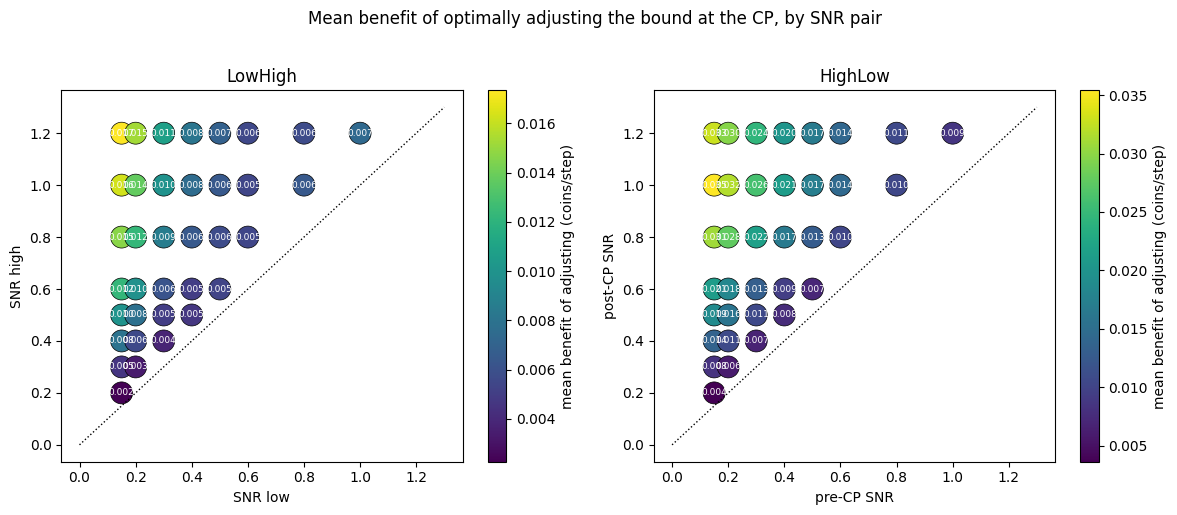

In [10]:

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for ax, direction in zip(axs, ['LowHigh', 'HighLow']):
    sub = agg[agg['direction'] == direction]
    sc = ax.scatter(sub['lo'], sub['hi'], c=sub['mean_benefit'], s=250, cmap='viridis',
                     edgecolors='k', linewidths=0.5)
    for _, r in sub.iterrows():
        ax.annotate(f"{r['mean_benefit']:.3f}", (r['lo'], r['hi']), fontsize=6.5,
                    ha='center', va='center', color='white')
    plt.colorbar(sc, ax=ax, label='mean benefit of adjusting (coins/step)')
    ax.plot([0, 1.3], [0, 1.3], 'k:', linewidth=1)
    ax.set_xlabel('pre-CP SNR' if direction == 'HighLow' else 'SNR low')
    ax.set_ylabel('post-CP SNR' if direction == 'HighLow' else 'SNR high')
    ax.set_title(direction)
plt.suptitle('Mean benefit of optimally adjusting the bound at the CP, by SNR pair', y=1.02)
plt.tight_layout()
plt.show()


### Interpretation

The **HighLow** direction (starting at high SNR, dropping to low SNR mid-trial) consistently
shows a larger benefit of adjusting than **LowHigh**, and larger SNR jumps generally increase
the benefit -- both make sense: if the bound doesn't loosen after evidence quality drops, the
participant keeps waiting for a level of certainty the new, noisier evidence can't deliver as
quickly, which is a bigger tax on reward rate than the reverse (having a slightly-too-loose
bound when evidence gets *better*, which mostly just costs a little extra time, not accuracy).

Within the historical ratio range (~1.2x-3.5x), the best pairs are all **HighLow**, with the
low end around SNR 0.15-0.4 and the high end around SNR 0.5-1.2. By mean absolute benefit,
0.3 -> 1.0 ranks first and 0.2 -> 0.6 sixth; by relative benefit, 0.15 -> 0.5 ranks first and
0.2 -> 0.6 fourth. The 2025 task's own pair (SNR 0.4 -> 0.2, ratio 2) ranks lower on both. Below
we take the 2025 pair as a baseline and compare it with two alternatives in more detail.


## Deep dive: finalist candidates

Three candidates, all **HighLow** (pre-CP high SNR -> post-CP low SNR), all within the
historical ratio range:

1. **2025 task** (SNR 0.4 -> 0.2, ratio 2) -- baseline for comparison.
2. **(0.6 -> 0.2, ratio 3)** -- keeps the same low-SNR anchor as the 2025 task, raises the
   high-SNR condition.
3. **(0.8 -> 0.3, ratio 2.67)** -- shifts both conditions up.

For each, compute the *full* benefit-of-adjusting curve across the whole `BOUND_GRID` of
pre-CP bounds (not just the 6 screening anchors), with a larger simulation budget
(`N_DEEPDIVE`) for a smoother estimate, plus the full (pre-bound x post-bound) RR heatmap.


In [11]:

FINALISTS = [
    ('2025 task', 0.4, 0.2),
    ('candidate A',  0.6, 0.2),
    ('candidate B',  0.8, 0.3),
]
N_DEEPDIVE = 300_000

rng = np.random.default_rng(RNG_SEED + 2)
deepdive_rows = []
heatmaps = {}
t0 = time.time()
for name, pre_snr, post_snr in FINALISTS:
    rr_grid = np.full((len(BOUND_GRID), len(BOUND_GRID)), np.nan)
    for pi, b_pre in enumerate(BOUND_GRID):
        switch_time, median_rt, timeout_frac, flag = feas.get(
            (pre_snr, b_pre)) or calibrate_fixed_block(pre_snr, b_pre, num_trials=N_CALIB, rng=rng)
        DV, ndts = simulate_cp_batch(pre_snr, post_snr, switch_time, N_DEEPDIVE, rng=rng)
        for qi, b_post in enumerate(BOUND_GRID):
            ch, rt = outcome_for_bounds(DV, ndts, b_pre, b_post, switch_time)
            rr_grid[pi, qi] = compute_rr(ch, rt, COINS_GAINED, COINS_LOST)
        ch0, rt0 = outcome_for_bounds(DV, ndts, b_pre, b_pre, switch_time)
        rr_noadjust = compute_rr(ch0, rt0, COINS_GAINED, COINS_LOST)
        best_i = int(np.nanargmax(rr_grid[pi]))
        deepdive_rows.append(dict(
            name=name, pre_snr=pre_snr, post_snr=post_snr, b_pre=b_pre, switch_time=switch_time,
            median_rt=median_rt, timeout_frac=timeout_frac, flag=flag,
            rr_noadjust=rr_noadjust, rr_opt=rr_grid[pi, best_i], b_post_opt=BOUND_GRID[best_i],
            benefit=max(rr_grid[pi, best_i] - rr_noadjust, 0.0),
        ))
    heatmaps[name] = rr_grid
print(f'Deep dive done in {time.time()-t0:.1f}s')
deepdive_df = pd.DataFrame(deepdive_rows)


Deep dive done in 15.4s


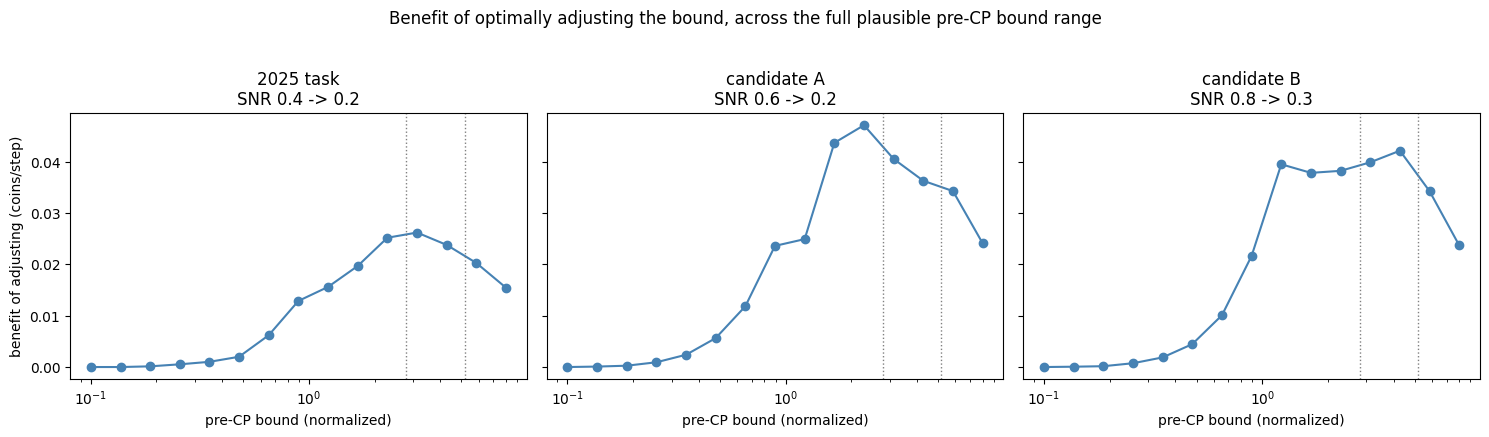

            benefit             
               mean  min     max
name                            
2025 task    0.0113  0.0  0.0262
candidate A  0.0197  0.0  0.0471
candidate B  0.0196  0.0  0.0421


In [12]:

fig, axs = plt.subplots(1, len(FINALISTS), figsize=(5 * len(FINALISTS), 4.2), sharey=True)
for ax, (name, pre_snr, post_snr) in zip(axs, FINALISTS):
    sub = deepdive_df[deepdive_df['name'] == name]
    ax.plot(sub['b_pre'], sub['benefit'], 'o-', color='steelblue')
    ax.set_xscale('log')
    ax.set_xlabel('pre-CP bound (normalized)')
    ax.set_title(f'{name}\nSNR {pre_snr} -> {post_snr}')
    for p, lbl in zip(np.percentile(_all_bounds / G_STD_PHYSICAL, [50, 90]), ['p50', 'p90']):
        ax.axvline(p, color='gray', linestyle=':', linewidth=1)
axs[0].set_ylabel('benefit of adjusting (coins/step)')
plt.suptitle('Benefit of optimally adjusting the bound, across the full plausible pre-CP bound range', y=1.03)
plt.tight_layout()
plt.show()

print(deepdive_df.groupby('name')[['benefit']].agg(['mean', 'min', 'max']).round(4))


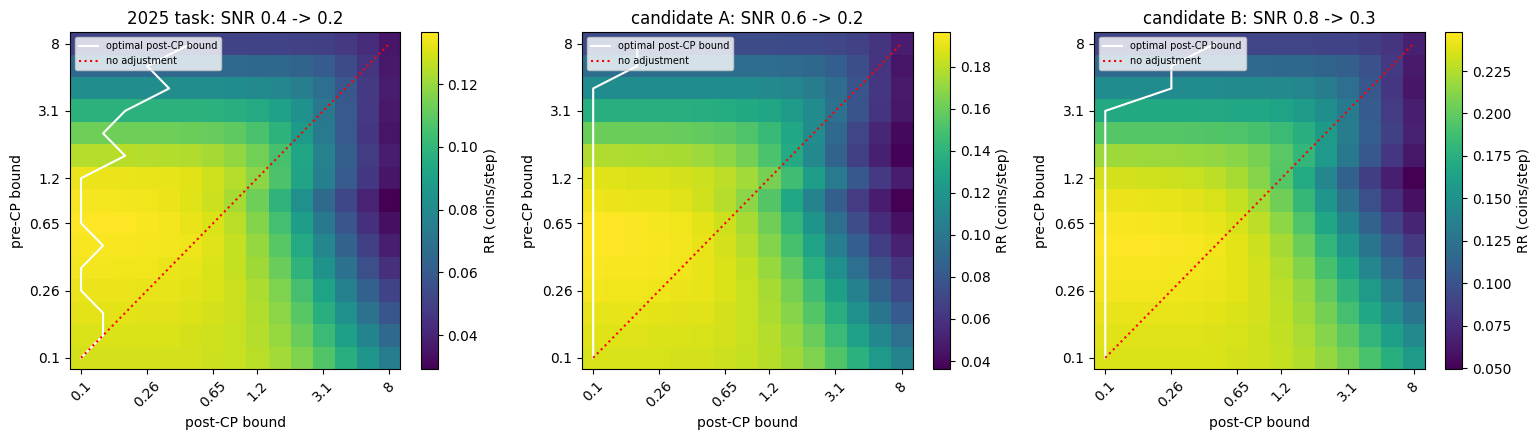

In [13]:

fig, axs = plt.subplots(1, len(FINALISTS), figsize=(5.2 * len(FINALISTS), 4.5))
tick_idx = np.linspace(0, len(BOUND_GRID) - 1, 6).round().astype(int)
tick_lbl = [f'{BOUND_GRID[k]:.2g}' for k in tick_idx]
for ax, (name, pre_snr, post_snr) in zip(axs, FINALISTS):
    im = ax.imshow(heatmaps[name], origin='lower', aspect='auto', cmap='viridis')
    plt.colorbar(im, ax=ax, label='RR (coins/step)')
    opt_post = np.nanargmax(heatmaps[name], axis=1)
    ax.plot(opt_post, range(len(BOUND_GRID)), 'w-', linewidth=1.5, label='optimal post-CP bound')
    ax.plot(range(len(BOUND_GRID)), range(len(BOUND_GRID)), 'r:', linewidth=1.5, label='no adjustment')
    ax.set_xticks(tick_idx); ax.set_xticklabels(tick_lbl, rotation=45)
    ax.set_yticks(tick_idx); ax.set_yticklabels(tick_lbl)
    ax.set_xlabel('post-CP bound'); ax.set_ylabel('pre-CP bound')
    ax.set_title(f'{name}: SNR {pre_snr} -> {post_snr}')
    ax.legend(fontsize=7, loc='upper left')
plt.tight_layout()
plt.show()


The white "optimal post-CP bound" curve sitting well below the red no-adjustment
diagonal, across the whole range of pre-CP bounds, is the visual signature we want: whatever
bound a participant happens to be using pre-CP, the reward-maximizing response to the SNR drop
is a *substantially* smaller bound, and candidates A/B widen that gap relative to the 2025
task.

### Robustness check: `coins_lost = 4` (the cost of the old reward-rate analysis)


In [14]:

rng = np.random.default_rng(RNG_SEED + 3)
robust_rows = []
for name, pre_snr, post_snr in FINALISTS:
    b_pre = 2.5  # representative pre-CP bound, the 2025 cohort's median bound (~2.5 normalized)
    switch_time, *_ = feas[(pre_snr, b_pre)] if (pre_snr, b_pre) in feas else calibrate_fixed_block(pre_snr, b_pre, rng=rng)
    DV, ndts = simulate_cp_batch(pre_snr, post_snr, switch_time, N_DEEPDIVE, rng=rng)
    for cost_label, coins_lost in [('cost=1 (task)', 1.0), ('cost=4 (old RR analysis)', 4.0)]:
        rr_curve = np.array([compute_rr(*outcome_for_bounds(DV, ndts, b_pre, b, switch_time), 1.0, coins_lost)
                              for b in BOUND_GRID])
        ch0, rt0 = outcome_for_bounds(DV, ndts, b_pre, b_pre, switch_time)
        rr_noadjust = compute_rr(ch0, rt0, 1.0, coins_lost)
        robust_rows.append(dict(name=name, cost=cost_label, b_pre=b_pre,
                                 benefit=max(rr_curve.max() - rr_noadjust, 0.0)))
print(pd.DataFrame(robust_rows).pivot(index='name', columns='cost', values='benefit').round(4))


cost         cost=1 (task)  cost=4 (old RR analysis)
name                                                
2025 task           0.0233                    0.0001
candidate A         0.0391                    0.0173
candidate B         0.0437                    0.0247


This is not just a robustness check that preserves the ranking -- it changes the story. At `coins_lost = 4` (the cost the old reward-rate analysis assumed), the **2025 task's** benefit of adjusting collapses to essentially zero (0.0001 coins/step) at this representative pre-CP bound, while candidates A and B retain most of their benefit (0.017-0.025). In other words, under the higher-penalty reward structure the 2025 SNR pair gives participants almost nothing to gain from adjusting their bound at the CP -- which is at least consistent with the old change-point analysis's finding that observed bound adjustment was weak and inconsistent across subjects. That is a substantive argument for changing the SNR pair, not just a sanity check on this notebook's own reward-structure assumption.


## Concrete recommendation

Converting the finalist normalized SNRs back to physical units (`x G_STD_PHYSICAL = 0.05`,
the MXSC calibration) gives direct `tc_step_mean` values for
`PigeonTaskConditions.xlsx`. `tc_step_std` is unchanged (0.05); it is the display-scale
constant, not part of the SNR search.


In [15]:

rec_rows = []
for name, pre_snr, post_snr in FINALISTS:
    lo, hi = sorted([pre_snr, post_snr])
    rec_rows.append(dict(
        name=name, snr_low=lo, snr_high=hi, ratio=hi / lo,
        tc_step_mean_low=round(lo * G_STD_PHYSICAL, 4),
        tc_step_mean_high=round(hi * G_STD_PHYSICAL, 4),
        tc_step_std=G_STD_PHYSICAL,
    ))
recommendation_df = pd.DataFrame(rec_rows)
print(recommendation_df.to_string(index=False))


       name  snr_low  snr_high    ratio  tc_step_mean_low  tc_step_mean_high  tc_step_std
  2025 task      0.2       0.4 2.000000             0.010               0.02         0.05
candidate A      0.2       0.6 3.000000             0.010               0.03         0.05
candidate B      0.3       0.8 2.666667             0.015               0.04         0.05


**Pilot recommendation**: run candidate A (SNR 0.6 -> 0.2, i.e. `tc_step_mean = 0.010,
0.030`) alongside the 2025 pair as a within-study comparison arm, or in its place if only
one pair is feasible for a first pilot. It's a one-parameter change (raise the high-SNR
`tc_step_mean` from 0.02 to 0.03; low-SNR condition and `tc_step_std` untouched), stays well
within the historical SNR range, passes the RT-extremity screen across the full plausible bound
range, and shows a meaningfully larger and more robust benefit-of-adjusting than the 2025
pair (deep dive: mean benefit about 0.020 vs. 0.011 coins/step). Candidate B does as well
(about 0.020) and is a reasonable alternative if a bigger absolute SNR shift is also of interest;
some pairs with a higher low-SNR end (e.g. 0.3 -> 1.0) rank higher still in the screening sweep.

### Caveats / next steps

- This is a **behavioral, non-normative, RR-based** design criterion (how much reward is at
  stake if bound adjustment fails to happen) -- it says nothing about whether a large
  behavioral difference will translate into a large *measured effect size* given the number of
  pilot trials available per participant; that still has to be checked empirically.
- `B_PRE_SCREEN` / `BOUND_GRID` are still just a grid over one nuisance parameter
  (assumed-fixed pre-CP bound); this doesn't model within-block bound variability
  (`bound_std`) or trial-to-trial SNR variability within a block.
- The reward structure (`coins_gained`/`coins_lost`) and `tc_steps_max` (block length) are
  taken as given from the 2025 conditions file; if those are also being redesigned, this
  sweep should be re-run with the updated values.
- Outcome: the 2026 cohort ran candidate A. Its change-point analysis uses the stopping model
  (`Figure06_cpSummary.ipynb`), not the reward-rate matrices this notebook refers to.
